# Notebook 05: Đánh giá Trước vs Sau cải thiện theo từng nhóm dữ liệu
Tất cả bảng đọc từ `results/tables/`. PSNR/SSIM/ΔE có tham chiếu GT; L̄ = $L^*$ trung bình; Crush0 = % pixel Y≤3; Clip255 = % pixel Y≥253.

In [1]:
import os, sys, cv2, pandas as pd
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))  # notebook đặt trong notebooks/
sys.path.insert(0, ROOT)
T = f"{ROOT}/results/tables"
pd.read_csv(f"{T}/table3_before_after_synthetic30.csv")

Method,PSNR (dB),SSIM,DeltaE_ab,Entropy (bits),Laplacian_Var,Pink_Cast (%),L_mean,Crush0 (%),Clip255 (%),Runtime (ms)
1. Ảnh đầu vào (suy giảm),20.35,0.7015,24.74,6.648,142.2,8.52,43.5,0.00,0.00,0.0
4. TRƯỚC cải thiện: Pipeline v1 (VGA),27.42,0.8180,10.06,6.917,186.9,5.61,36.6,3.88,0.02,14573.1
7. SAU cải thiện: Pipeline v2 (3 giai đoạn - VGA),25.39,0.6996,14.55,7.200,215.6,0.41,36.5,0.92,0.00,21210.2


In [2]:
pd.read_csv(f"{T}/table4_before_after_augmented.csv")

Scenario,Method,PSNR (dB),SSIM,DeltaE_ab,Entropy (bits),Laplacian_Var,Pink_Cast (%),L_mean,Crush0 (%),Clip255 (%),Runtime (ms)
haze_pink,1. Ảnh đầu vào (suy giảm),15.84,0.7360,42.38,6.323,84.6,10.07,50.5,0.00,0.00,0.0
haze_pink,4. TRƯỚC cải thiện: Pipeline v1 (VGA),20.36,0.8001,25.03,6.940,269.8,3.91,43.5,1.82,0.13,13828.0
haze_pink,7. SAU cải thiện: Pipeline v2 (3 giai đoạn - VGA),25.22,0.8312,15.98,7.135,183.8,1.62,36.5,0.92,0.00,15229.7
low_light,1. Ảnh đầu vào (suy giảm),14.32,0.3710,52.32,5.924,1506.6,0.00,16.6,0.84,0.00,0.0
low_light,4. TRƯỚC cải thiện: Pipeline v1 (VGA),10.82,0.1678,79.96,3.901,140.7,0.00,4.3,51.41,0.00,13986.1
low_light,7. SAU cải thiện: Pipeline v2 (3 giai đoạn - VGA),18.25,0.5028,32.51,6.336,1765.3,0.08,30.9,0.06,0.00,21628.1
backlit_uneven,1. Ảnh đầu vào (suy giảm),16.86,0.7649,35.01,6.617,104.0,0.29,22.7,2.33,0.05,0.0
backlit_uneven,4. TRƯỚC cải thiện: Pipeline v1 (VGA),13.51,0.4253,53.62,5.682,234.8,0.48,15.1,29.38,0.13,13928.6
backlit_uneven,7. SAU cải thiện: Pipeline v2 (3 giai đoạn - VGA),17.24,0.7600,34.13,6.959,119.2,0.08,28.0,1.49,0.00,15414.3
motion_jpeg,1. Ảnh đầu vào (suy giảm),28.67,0.7748,7.21,6.650,22.1,0.73,34.9,2.45,0.00,0.0


In [3]:
pd.read_csv(f"{T}/table5_before_after_real60.csv")

Method,Entropy (bits),Laplacian_Var,Pink_Cast (%),L_mean,Crush0 (%),Clip255 (%),Runtime (ms)
1. Ảnh đầu vào (suy giảm),6.364,121.1,17.45,51.1,0.00,0.00,0.0
4. TRƯỚC cải thiện: Pipeline v1 (VGA),6.850,226.5,7.03,44.9,1.94,0.07,15424.0
7. SAU cải thiện: Pipeline v2 (3 giai đoạn - VGA),7.159,186.5,1.38,44.6,0.38,0.00,21669.1


In [4]:
pd.read_csv(f"{T}/table6_real_dark_pink_cases.csv")

Image,Method,L_mean,Crush0 (%),Clip255 (%),Pink_Cast (%),Entropy (bits),Laplacian_Var
esp32_real_001.jpg,1. Ảnh đầu vào (suy giảm),60.69,0.00,0.00,32.53,7.01,213.44
esp32_real_001.jpg,4. TRƯỚC cải thiện: Pipeline v1 (VGA),57.72,0.00,0.19,15.83,7.46,474.36
esp32_real_001.jpg,7. SAU cải thiện: Pipeline v2 (3 giai đoạn - VGA),55.65,0.13,0.00,1.01,7.74,361.21
esp32_real_013.jpg,1. Ảnh đầu vào (suy giảm),68.39,0.00,0.00,69.63,6.99,138.50
esp32_real_013.jpg,4. TRƯỚC cải thiện: Pipeline v1 (VGA),68.06,0.00,0.02,12.91,7.39,195.58
esp32_real_013.jpg,7. SAU cải thiện: Pipeline v2 (3 giai đoạn - VGA),59.35,0.68,0.00,0.12,7.79,220.30
esp32_real_032.jpg,1. Ảnh đầu vào (suy giảm),66.48,0.00,0.00,45.92,7.10,182.61
esp32_real_032.jpg,4. TRƯỚC cải thiện: Pipeline v1 (VGA),65.05,0.00,0.02,9.76,7.47,469.93
esp32_real_032.jpg,7. SAU cải thiện: Pipeline v2 (3 giai đoạn - VGA),65.90,0.08,0.00,0.07,7.62,265.98
esp32_real_051.jpg,1. Ảnh đầu vào (suy giảm),33.63,0.00,0.00,0.37,3.81,6.00


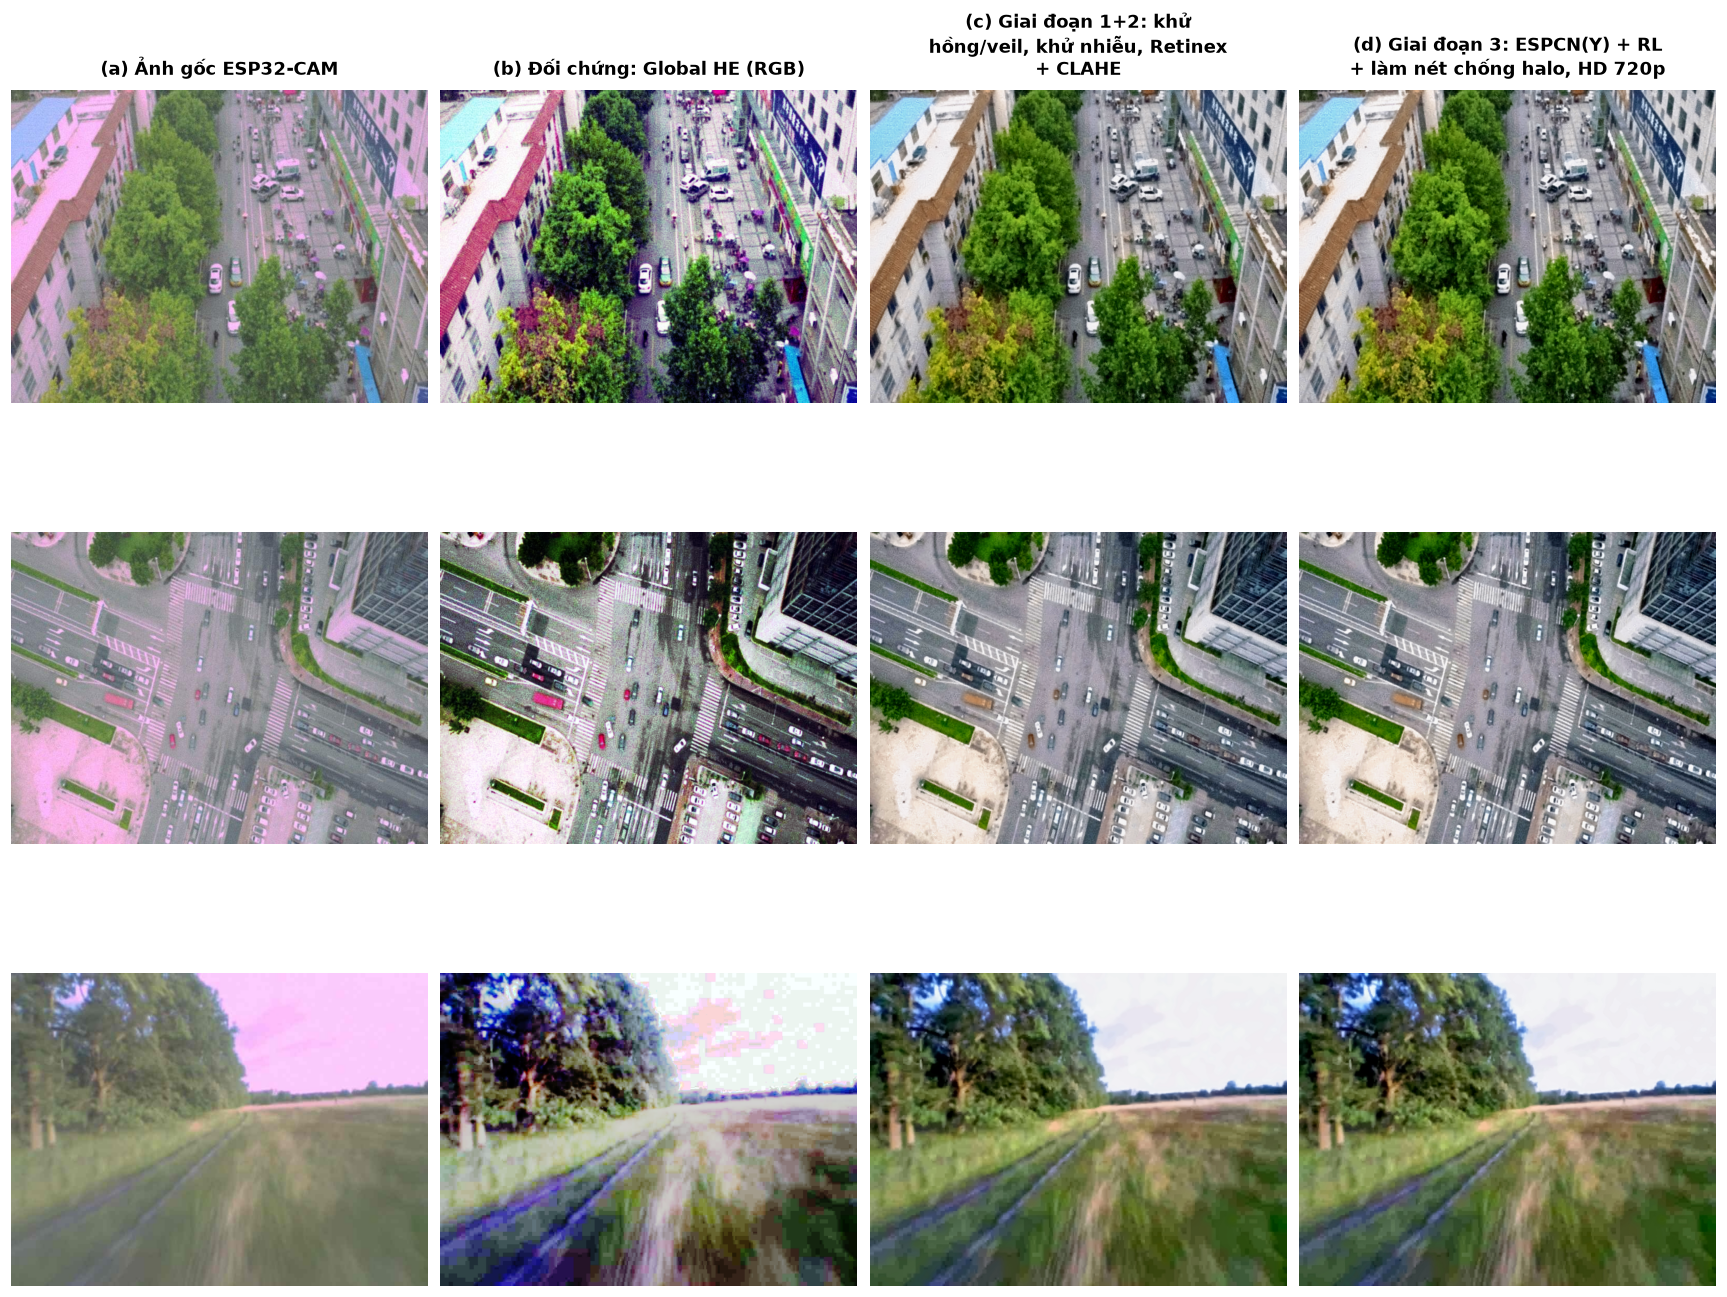

In [5]:
# Lưới 4 cột (Mục 4.1)